# Accepted originals and treated trajectories

correlation      rmse   acf_mae  std_ratio
retention method                                              
False     heaps        0.239802  1.233043  0.313006   2.461967
          jacobian     0.890322  0.468355  0.044518   0.879173
          shao_wu      0.912831  0.417538  0.042759   0.881434
True      heaps        0.155272  1.299789  0.341922   1.404275
          jacobian     0.709557  0.762113  0.146230   0.690438
          shao_wu      0.946326  0.327641  0.039169   0.862478

[{'retention': True, 'candidates': 300, 'accepted': 252, 'history_attempts': 459}, {'retention': False, 'candidates': 300, 'accepted': 175, 'history_attempts': 719}]


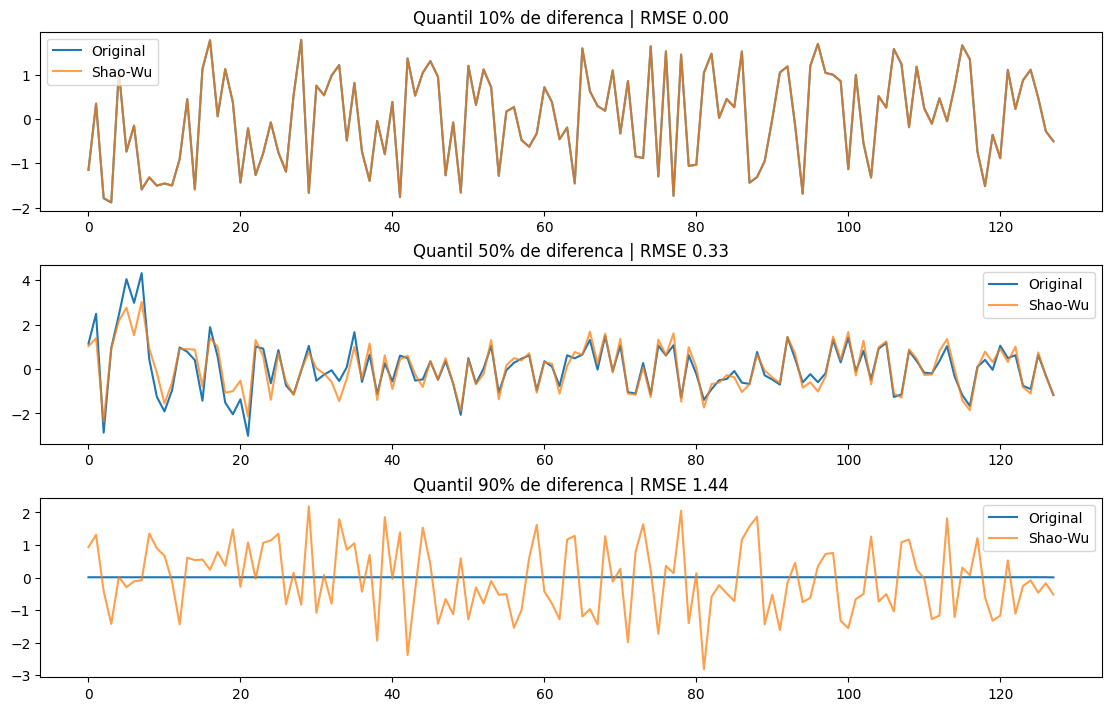

In [1]:
from pathlib import Path
import sys,json,time,platform,hashlib
from dataclasses import asdict,replace
import numpy as np,pandas as pd,matplotlib.pyplot as plt
root=next(p for p in (Path.cwd(),*Path.cwd().parents) if (p/'pyproject.toml').exists())
sys.path.insert(0,str(root/'src'))
from tsfmxai.generators.multiseries import *
from tsfmxai.generators.combinatorial_expression import CombinatorialTreeConfig
from tsfmxai.generators.initialization import RandomHistorySpec,sample_random_history
from tsfmxai.generators.stochastic import simulate_innovation_path
cfg=MultiseriesConfig(ast_config=CombinatorialTreeConfig(maximum_operators=4,maximum_lag=16,max_degree=4),channel_count_probs={1:1.},dependency_probs={'independent':1.},treatment_probs={'original':1.})
def z(x):return (x-x.mean())/(x.std()+1e-12)
def acf(x):return np.array([np.mean(z(x)[:-k]*z(x)[k:]) for k in (1,2,4,8,16)])
rows=[];counts=[];examples=[];start=time.perf_counter()
for retention in (True,False):
 accepted_count=0;attempts=0
 for i in range(300):
    s=sample_multiseries_system(replace(cfg,lag_retention=cfg.lag_retention if retention else None),seed=stream_seed(314159,i))
    noise=np.random.default_rng(stream_seed(314159,i,90)).uniform(-np.sqrt(3)*.05,np.sqrt(3)*.05,(1,256))
    for attempt in range(4):
        attempts+=1
        h,_=sample_random_history(RandomHistorySpec(),1,s.history_length,np.random.default_rng(stream_seed(314159,i,91,attempt)))
        x=simulate_innovation_path(s.expressions,s.bindings,h,noise)
        accepted=x.shape[1]==256 and np.isfinite(x).all() and np.max(np.abs(x))<np.finfo(np.float32).max
        if accepted:break
    if not accepted:continue
    accepted_count+=1
    for method in ('shao_wu','jacobian','heaps'):
        if method=='jacobian' and not s.history_length:continue
        t=build_multiseries_system(equations=s.original_equations,allowed_sources={0:[0]},treatments=[TreatmentSpec(method)],innovations=[InnovationSpec('uniform' if method=='jacobian' else 'gaussian',.05)],max_degree=4)
        # Heaps may introduce memory for constant originals.
        history=h if h.shape[1]>=t.history_length else np.zeros((1,t.history_length))
        y=simulate_innovation_path(t.expressions,t.bindings,history,noise)
        assert y.shape==x.shape and np.isfinite(y).all()
        a,b=z(x[0]),z(y[0])
        row=dict(retention=retention,index=i,method=method,correlation=float(np.mean(a*b)),rmse=float(np.sqrt(np.mean((a-b)**2))),acf_mae=float(np.mean(np.abs(acf(x[0])-acf(y[0])))),std_ratio=float(y.std()/(x.std()+1e-12)),original_acf=acf(x[0]).tolist(),treated_acf=acf(y[0]).tolist())
        rows.append(row)
        if retention and method=='shao_wu':examples.append((row['rmse'],a,b))
 counts.append(dict(retention=retention,candidates=300,accepted=accepted_count,history_attempts=attempts))
df=pd.DataFrame(rows)
summary=df.groupby(['retention','method'])[['correlation','rmse','acf_mae','std_ratio']].median()
display(summary);print(counts)
fig,axes=plt.subplots(3,1,figsize=(11,7),layout='constrained')
cases=sorted(examples,key=lambda t:t[0])
for ax,q in zip(axes,[.1,.5,.9]):
 d,a,b=cases[int(q*(len(cases)-1))]
 ax.plot(a[:128],label='Original');ax.plot(b[:128],label='Shao-Wu',alpha=.75);ax.set_title(f'Quantil {q:.0%} de diferenca | RMSE {d:.2f}');ax.legend()
plt.show()


In [2]:
# COMPLETE EXPERIMENT RECORD
record=dict(question='Does treating an accepted original preserve normalized temporal shape?',hypothesis='Some temporal dependence is lost beyond amplitude scaling.',configuration=asdict(cfg),candidates_per_arm=300,retention_arms=[True,False],seed=314159,seed_policy='system stream_seed(root,i), noise(root,i,90), history(root,i,91,attempt)',steps=256,history_attempts_max=4,initialization=asdict(RandomHistorySpec()),controlled_noise='shared uniform +/-sqrt(3)*.05 across all methods',normalization='per trajectory zero mean unit std',counts=counts,metrics=rows,summary=summary.reset_index().to_dict('records'),elapsed_seconds=time.perf_counter()-start,provenance=dict(python=sys.version,platform=platform.platform(),sha256={str(p.relative_to(root)):hashlib.sha256(p.read_bytes()).hexdigest() for p in (root/'src/tsfmxai/generators').glob('*.py')}),limitations=['Univariate finite horizon exploratory study','Heaps constructs a different AR and constant originals need zero initialization for its added lag','Shared bounded innovations control the comparison but differ from default Gaussian law for Shao-Wu and Heaps','Jacobian comparison excludes originals with no memory','Shared noise can increase correlation','No joint coverage or training quality conclusion'],scientific_summary='Inspect paired normalized RMSE and ACF differences. Counts quantify original acceptance before whole-system replacement.',reproduction='python -m jupyter nbconvert --execute --to notebook --inplace --ExecutePreprocessor.timeout=-1 experiments/multivariate_generation/03_accepted_original_diversity/01_paired.ipynb')
print(json.dumps(record))


{"question": "Does treating an accepted original preserve normalized temporal shape?", "hypothesis": "Some temporal dependence is lost beyond amplitude scaling.", "configuration": {"ast_config": {"minimum_operators": 1, "maximum_operators": 4, "num_series": 1, "minimum_lag": 1, "maximum_lag": 16, "max_degree": 4, "require_lag": true, "minimum_parameter_magnitude": 0.05, "maximum_parameter_magnitude": 0.9}, "channel_count_probs": {"1": 1.0}, "dependency_probs": {"independent": 1.0}, "treatment_probs": {"original": 1.0}, "max_external_sources": 2, "self_source_weight": 3.0, "allow_no_lags": true, "noise": {"std_range": [0.01, 0.1], "std_sampling": "uniform", "family_policy": "by_treatment"}, "target_gain": 0.8, "safety_factor": 0.95, "lag_retention": {"minimum": 0.5, "maximum": 1.0, "tau": 1.0}}, "candidates_per_arm": 300, "retention_arms": [true, false], "seed": 314159, "seed_policy": "system stream_seed(root,i), noise(root,i,90), history(root,i,91,attempt)", "steps": 256, "history_atte